In [12]:
# Загрузка параметров и динамическое оформление постановки задачи.
from pathlib import Path
import json, math, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
repo_root = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(repo_root))
from utils.calculations import critical_mass, users_path, cash_flow_table, npv, break_even_arpu
with open(repo_root / 'data' / 'task_02_social_network_config.json', encoding='utf-8') as file:
    cfg = json.load(file)
plt.style.use('default')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.color': '#D9D9D9', 'figure.dpi': 120})
pd.set_option('display.float_format', lambda value: f'{value:,.2f}'.replace(',', ' ').replace('.', ','))
figures_dir = repo_root / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
def fmt_num(value, decimals=0):
    return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
def fmt_pct(value, decimals=0):
    return f'{value:.{decimals}%}'.replace('.', ',')
def fmt_rub(value, decimals=0):
    return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
intro = f"""# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №{cfg['task_id']}: {cfg['title']}

## Условие задачи

Компания «{cfg['project_name']}» запускает социальную сеть для жителей города с потенциалом рынка **{fmt_num(cfg['market_potential_users'])} чел.** Необходимо оценить экономическую ценность сети и определить момент достижения критической массы.

## Экономическая постановка

Исследование включает расчёт критической массы, времени её достижения, сетевой ценности по закону Мэткалфа, помесячной прибыли, NPV, сценарного анализа, минимального ARPU и объёма маркетинговых инвестиций для ускорения роста.

Все числовые параметры загружаются из JSON. Поэтому при их изменении таблицы, расчёты и выводы Notebook пересчитываются автоматически."""
display(Markdown(intro))

# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №2: Расчет критической массы и ценности социальной сети

## Условие задачи

Компания «ГородСоцСеть» запускает социальную сеть для жителей города с потенциалом рынка **1 000 000 чел.** Необходимо оценить экономическую ценность сети и определить момент достижения критической массы.

## Экономическая постановка

Исследование включает расчёт критической массы, времени её достижения, сетевой ценности по закону Мэткалфа, помесячной прибыли, NPV, сценарного анализа, минимального ARPU и объёма маркетинговых инвестиций для ускорения роста.

Все числовые параметры загружаются из JSON. Поэтому при их изменении таблицы, расчёты и выводы Notebook пересчитываются автоматически.

## Исходные данные и допущения

В строгой модели новые пользователи появляются пропорционально текущей базе:

```text
ΔN = g × N
```

Поэтому CAC является переменными затратами, зависящими от текущего прироста. Пользовательская база ограничена потенциалом рынка, отток и налоги не моделируются, а ARPU трактуется как денежный доход на одного пользователя до не заданных в условии переменных расходов.

In [13]:
input_data = pd.DataFrame([
    ('Потенциал рынка', cfg['market_potential_users'], 'чел.'),
    ('Начальные пользователи', cfg['initial_users'], 'чел.'),
    ('Рост до критической массы', cfg['growth_before_critical'], '%/мес.'),
    ('Рост после критической массы', cfg['growth_after_critical'], '%/мес.'),
    ('Коэффициент Мэткалфа', cfg['network_value_coefficient_rub_per_user_squared'], 'руб./пользователь²'),
    ('Поддержание сети', cfg['monthly_maintenance_cost_rub'], 'руб./мес.'),
    ('Исходный CAC', cfg['cac_rub'], 'руб./пользователь'),
    ('Операционный CAC', cfg['operational_cac_rub'], 'руб./пользователь'),
    ('ARPU', cfg['arpu_rub_per_user_month'], 'руб./пользователь/мес.'),
    ('Горизонт', cfg['horizon_months'], 'мес.'),
    ('Ставка дисконтирования', cfg['monthly_discount_rate'], '%/мес.'),
], columns=['Параметр','Значение','Единица измерения'])
input_data.loc[input_data['Единица измерения'].str.contains('%'), 'Значение'] *= 100
display(input_data)

,Параметр,Значение,Единица измерения
0,Потенциал рынка,"1 000 000,00",чел.
1,Начальные пользователи,"5 000,00",чел.
2,Рост до критической массы,"15,00",%/мес.
3,Рост после критической массы,"15,00",%/мес.
4,Коэффициент Мэткалфа,"0,01",руб./пользователь²
5,Поддержание сети,"2 000 000,00",руб./мес.
6,Исходный CAC,"50,00",руб./пользователь
7,Операционный CAC,"30,00",руб./пользователь
8,ARPU,"30,00",руб./пользователь/мес.
9,Горизонт,"36,00",мес.


## Часть 1. Расчёт критической массы
### Вопрос 1
Определить минимальное число пользователей, при котором ежемесячная прибыль становится неотрицательной при текущем темпе роста.

In [14]:
g = cfg['growth_before_critical']
operational_cac = cfg['operational_cac_rub']

def strict_critical_mass(arpu, maintenance, cac, growth):
    new_user_share = growth / (1 + growth)
    contribution_margin = arpu - cac * new_user_share
    if contribution_margin <= 0:
        return math.inf
    return maintenance / contribution_margin

def months_to_target(target, growth, initial):
    if not math.isfinite(target): return math.inf
    if target <= initial: return 0
    return math.ceil(math.log(target / initial) / math.log(1 + growth))

def critical_mass_text(value):
    return 'не существует при данных параметрах' if not math.isfinite(value) else fmt_num(value)

strict_critical = strict_critical_mass(cfg['arpu_rub_per_user_month'], cfg['monthly_maintenance_cost_rub'], cfg['cac_rub'], g)
operational_critical = strict_critical_mass(cfg['arpu_rub_per_user_month'], cfg['monthly_maintenance_cost_rub'], operational_cac, g)
strict_within_market = math.isfinite(strict_critical) and strict_critical <= cfg['market_potential_users']
operational_within_market = math.isfinite(operational_critical) and operational_critical <= cfg['market_potential_users']
strict_months = months_to_target(strict_critical, g, cfg['initial_users'])
operational_months = months_to_target(operational_critical, g, cfg['initial_users'])
critical_table = pd.DataFrame({
    'Сценарий': [f"Исходный CAC = {fmt_rub(cfg['cac_rub'])} руб.", f"Операционный CAC = {fmt_rub(operational_cac)} руб."],
    'Маржинальный вклад пользователя, руб.': [cfg['arpu_rub_per_user_month'] - cfg['cac_rub'] * g / (1 + g), cfg['arpu_rub_per_user_month'] - operational_cac * g / (1 + g)],
    'Критическая масса, чел.': [critical_mass_text(strict_critical), critical_mass_text(operational_critical)],
    'Достижима в рынке': ['Да' if strict_within_market else 'Нет' if math.isfinite(strict_critical) else 'Нет', 'Да' if operational_within_market else 'Нет'],
    'Месяц достижения': ['не достигается' if not strict_within_market else strict_months, 'не достигается' if not operational_within_market else operational_months]
})
display(critical_table)
strict_new_user_share = g / (1 + g)
operational_new_user_share = g / (1 + g)
strict_margin = cfg['arpu_rub_per_user_month'] - cfg['cac_rub'] * strict_new_user_share
strict_interpretation = ('критическая масса не существует, так как маржинальный вклад пользователя не положителен.' if not math.isfinite(strict_critical) else ('критическая масса существует, но превышает потенциал рынка.' if not strict_within_market else 'критическая масса существует и достижима в пределах рынка.'))
operational_margin = cfg['arpu_rub_per_user_month'] - operational_cac * operational_new_user_share
formula = f"""**Строгая формула:**

Прибыль(N) = ARPU × N − Cmaint − CAC × (g/(1+g) × N)

Nкрит = Cmaint / (ARPU − CAC × g/(1+g)), если ARPU − CAC × g/(1+g) > 0.

Для исходного CAC: ARPU − CAC × g/(1+g) = {fmt_rub(cfg['arpu_rub_per_user_month'])} − {fmt_rub(cfg['cac_rub'])} × ({fmt_pct(g)} / (1 + {fmt_pct(g)})) = **{fmt_rub(strict_margin, 2)} руб.** на пользователя. **{strict_interpretation}**

Для операционного CAC: Nкрит = {fmt_rub(cfg['monthly_maintenance_cost_rub'])} / ({fmt_rub(cfg['arpu_rub_per_user_month'])} − {fmt_rub(operational_cac)} × ({fmt_pct(g)} / (1 + {fmt_pct(g)}))) = **{fmt_num(operational_critical)} пользователей**.

**Вывод:** {('исходный сценарий не может стать самоподдерживающимся при любом размере базы.' if not math.isfinite(strict_critical) else 'исходный порог существует.')} Операционный сценарий требует снижения CAC до {fmt_rub(operational_cac)} руб. и достигает порога через **{operational_months} месяцев**, если он находится в пределах рынка."""
display(Markdown(formula))

,Сценарий,"Маржинальный вклад пользователя, руб.","Критическая масса, чел.",Достижима в рынке,Месяц достижения
0,Исходный CAC = 50 руб.,"23,48",85 185,Да,21
1,Операционный CAC = 30 руб.,"26,09",76 667,Да,20


**Строгая формула:**

Прибыль(N) = ARPU × N − Cmaint − CAC × (g/(1+g) × N)

Nкрит = Cmaint / (ARPU − CAC × g/(1+g)), если ARPU − CAC × g/(1+g) > 0.

Для исходного CAC: ARPU − CAC × g/(1+g) = 30 − 50 × (15% / (1 + 15%)) = **23,48 руб.** на пользователя. **критическая масса существует и достижима в пределах рынка.**

Для операционного CAC: Nкрит = 2 000 000 / (30 − 30 × (15% / (1 + 15%))) = **76 667 пользователей**.

**Вывод:** исходный порог существует. Операционный сценарий требует снижения CAC до 30 руб. и достигает порога через **20 месяцев**, если он находится в пределах рынка.

### Вопрос 2
Рассчитать, через сколько месяцев сеть достигнет критической массы при росте до и после порога.

In [15]:
if math.isfinite(operational_critical):
    target_month_exact = math.log(operational_critical / cfg['initial_users']) / math.log(1 + g)
    target_month = math.ceil(target_month_exact)
    check_months = sorted(set([0, min(cfg['horizon_months'], 12), min(cfg['horizon_months'], 24), cfg['horizon_months'], max(0, target_month - 1), target_month]))
    check_table = pd.DataFrame({'Месяц': check_months, 'Расчёт пользователей': [cfg['initial_users'] * (1 + g) ** month for month in check_months]})
    check_table['Сравнение с N крит'] = np.where(check_table['Расчёт пользователей'] >= operational_critical, 'не ниже порога', 'ниже порога')
    display(check_table)
    display(Markdown(f"""До порога используется N(t) = N₀ × (1 + g)^t.

Подстановка: {fmt_num(operational_critical)} = {fmt_num(cfg['initial_users'])} × (1 + {fmt_pct(g)})^t.

Точное значение t = **{target_month_exact:.2f} месяца**, поэтому по целым месяцам порог достигается на **{target_month}-м месяце**. После порога используется рост **{fmt_pct(cfg['growth_after_critical'])}** в месяц. Строгий исходный сценарий: {('критическая масса не существует.' if not math.isfinite(strict_critical) else ('критическая масса превышает потенциал рынка и недостижима.' if not strict_within_market else f'порог достигается на {strict_months}-м месяце.'))}"""))
else:
    display(Markdown('Критическая масса не существует при заданных параметрах, поэтому срок её достижения не определяется.'))

,Месяц,Расчёт пользователей,Сравнение с N крит
0,0,"5 000,00",ниже порога
1,12,"26 751,25",ниже порога
2,19,"71 158,86",ниже порога
3,20,"81 832,69",не ниже порога
4,24,"143 125,88",не ниже порога
5,36,"765 759,26",не ниже порога


До порога используется N(t) = N₀ × (1 + g)^t.

Подстановка: 76 667 = 5 000 × (1 + 15%)^t.

Точное значение t = **19.53 месяца**, поэтому по целым месяцам порог достигается на **20-м месяце**. После порога используется рост **15%** в месяц. Строгий исходный сценарий: порог достигается на 21-м месяце.

## Часть 2. Оценка ценности сети
### Вопросы 3–5
Рассчитать ценность сети по закону Мэткалфа, доход пользователей и прибыль сети.

In [16]:
users = users_path(cfg['initial_users'], cfg['growth_before_critical'], cfg['growth_after_critical'], operational_critical if math.isfinite(operational_critical) else cfg['market_potential_users'] + 1, cfg['horizon_months'], cfg['market_potential_users'])
rows = cash_flow_table(users, cfg['arpu_rub_per_user_month'], cfg['monthly_maintenance_cost_rub'], operational_cac)
df = pd.DataFrame(rows)
df['network_value'] = cfg['network_value_coefficient_rub_per_user_squared'] * df['users'] ** 2
df['discount_factor'] = 1 / ((1 + cfg['monthly_discount_rate']) ** df['month'])
df['discounted_profit'] = df['profit'] * df['discount_factor']
display_df = df.rename(columns={'month':'Месяц','users':'Пользователи, чел.','new_users':'Новые пользователи, чел.','revenue':'Выручка, руб.','maintenance':'Поддержание, руб.','acquisition_cost':'Привлечение, руб.','profit':'Прибыль, руб.','network_value':'Ценность сети, руб.','discount_factor':'Коэффициент дисконтирования','discounted_profit':'Дисконтированная прибыль, руб.'})
display(display_df.head(min(13, len(display_df))))
summary = pd.DataFrame({'Показатель':['Пользователи в конце горизонта','Ценность при N крит','Ценность при полном охвате','Выручка при N крит','Прибыль при N крит'],'Значение':[users[-1],cfg['network_value_coefficient_rub_per_user_squared']*operational_critical**2 if math.isfinite(operational_critical) else math.nan,cfg['network_value_coefficient_rub_per_user_squared']*cfg['market_potential_users']**2,cfg['arpu_rub_per_user_month']*operational_critical if math.isfinite(operational_critical) else math.nan,cfg['arpu_rub_per_user_month']*operational_critical-cfg['monthly_maintenance_cost_rub']-operational_cac*g*operational_critical if math.isfinite(operational_critical) else math.nan],'Единица':['чел.','руб.','руб.','руб./мес.','руб./мес.']})
display(summary)

,Месяц,"Пользователи, чел.","Новые пользователи, чел.","Выручка, руб.","Поддержание, руб.","Привлечение, руб.","Прибыль, руб.","Ценность сети, руб.",Коэффициент дисконтирования,"Дисконтированная прибыль, руб."
0,0,"5 000,00","0,00","150 000,00",2000000,"0,00","-1 850 000,00","125 000,00","1,00","-1 850 000,00"
1,1,"5 750,00","750,00","172 500,00",2000000,"22 500,00","-1 850 000,00","165 312,50","0,99","-1 831 683,17"
2,2,"6 612,50","862,50","198 375,00",2000000,"25 875,00","-1 827 500,00","218 625,78","0,98","-1 791 491,03"
3,3,"7 604,37","991,87","228 131,25",2000000,"29 756,25","-1 801 625,00","289 132,60","0,97","-1 748 639,48"
4,4,"8 745,03","1 140,66","262 350,94",2000000,"34 219,69","-1 771 868,75","382 377,86","0,96","-1 702 731,04"
5,5,"10 056,79","1 311,75","301 703,58",2000000,"39 352,64","-1 737 649,06","505 694,72","0,95","-1 653 313,46"
6,6,"11 565,30","1 508,52","346 959,11",2000000,"45 255,54","-1 698 296,42","668 781,26","0,94","-1 599 872,05"
7,7,"13 300,10","1 734,80","399 002,98",2000000,"52 043,87","-1 653 040,89","884 463,22","0,93","-1 541 821,08"
8,8,"15 295,11","1 995,01","458 853,43",2000000,"59 850,45","-1 600 997,02","1 169 702,61","0,92","-1 478 493,89"
9,9,"17 589,38","2 294,27","527 681,44",2000000,"68 828,01","-1 541 146,57","1 546 931,70","0,91","-1 409 131,68"


,Показатель,Значение,Единица
0,Пользователи в конце горизонта,"765 759,26",чел.
1,Ценность при N крит,"29 388 888,89",руб.
2,Ценность при полном охвате,"5 000 000 000,00",руб.
3,Выручка при N крит,"2 300 000,00",руб./мес.
4,Прибыль при N крит,"-45 000,00",руб./мес.


## Часть 3. Анализ эффективности
### Вопросы 6–8
Рассчитать NPV проекта на заданном горизонте, сравнить сценарии роста и определить минимальный ARPU для безубыточности.

In [17]:
def simulate(arpu, cac, growth_before, growth_after, horizon=None):
    horizon = cfg['horizon_months'] if horizon is None else horizon
    critical = strict_critical_mass(arpu, cfg['monthly_maintenance_cost_rub'], cac, growth_before)
    target = critical if math.isfinite(critical) else cfg['market_potential_users'] + 1
    path = users_path(cfg['initial_users'], growth_before, growth_after, target, horizon, cfg['market_potential_users'])
    table = pd.DataFrame(cash_flow_table(path, arpu, cfg['monthly_maintenance_cost_rub'], cac))
    return critical, path, table, npv(table['profit'].iloc[1:], cfg['monthly_discount_rate'])
strict_critical, strict_users, strict_df, strict_npv = simulate(cfg['arpu_rub_per_user_month'], cfg['cac_rub'], cfg['growth_before_critical'], cfg['growth_after_critical'])
operational_critical, operational_users, operational_df, base_npv = simulate(cfg['arpu_rub_per_user_month'], operational_cac, cfg['growth_before_critical'], cfg['growth_after_critical'])
npv_table = pd.DataFrame({'Сценарий':['Строгий CAC','Операционный CAC'],'NPV, руб.':[strict_npv,base_npv],'Интерпретация':['CAC из условия задачи; ARPU − CAC × рост ≤ 0','Отдельный сценарий снижения CAC']})
display(npv_table)
display(Markdown(f"**Ответ на вопрос 6:** основной помесячный NPV операционного сценария за {cfg['horizon_months']} месяцев равен **{fmt_rub(base_npv, 2)} руб.** при ставке **{fmt_pct(cfg['monthly_discount_rate'], 1)} в месяц**. Строгий сценарий даёт **{fmt_rub(strict_npv, 2)} руб.** и не достигает самоокупаемости."))

,Сценарий,"NPV, руб.",Интерпретация
0,Строгий CAC,"42 039 438,52",CAC из условия задачи; ARPU − CAC × рост ≤ 0
1,Операционный CAC,"53 401 043,92",Отдельный сценарий снижения CAC


**Ответ на вопрос 6:** основной помесячный NPV операционного сценария за 36 месяцев равен **53 401 043,92 руб.** при ставке **1,0% в месяц**. Строгий сценарий даёт **42 039 438,52 руб.** и не достигает самоокупаемости.

In [18]:
scenario_rows = []
scenario_dfs = {}
for name, scenario in cfg['scenarios'].items():
    before, after = scenario['growth_before'], scenario['growth_after']
    scenario_critical, path, table, scenario_npv = simulate(cfg['arpu_rub_per_user_month'], operational_cac, before, after)
    scenario_dfs[name] = table
    scenario_rows.append({'Сценарий':name,'Рост до / после':f'{fmt_pct(before)} / {fmt_pct(after)}','Пользователи в конце':path[-1],'NPV, руб.':scenario_npv,'Критическая масса, чел.':critical_mass_text(scenario_critical),'Месяц критической массы':months_to_target(scenario_critical,before,cfg['initial_users']) if math.isfinite(scenario_critical) and scenario_critical <= cfg['market_potential_users'] else 'не достигается'})
scenario_table = pd.DataFrame(scenario_rows)
display(scenario_table)

def npv_at_arpu(arpu):
    return simulate(arpu, operational_cac, cfg['growth_before_critical'], cfg['growth_after_critical'])[3]
def npv_at_cac(cac):
    return simulate(cfg['arpu_rub_per_user_month'], cac, cfg['growth_before_critical'], cfg['growth_after_critical'])[3]
def npv_at_growth(growth):
    return simulate(cfg['arpu_rub_per_user_month'], operational_cac, growth, cfg['growth_after_critical'])[3]
def binary_threshold(function, low, high):
    if function(high) < 0: return math.inf
    for _ in range(60):
        mid=(low+high)/2
        if function(mid)>=0: high=mid
        else: low=mid
    return high
min_arpu = binary_threshold(npv_at_arpu, 0, max(100, cfg['arpu_rub_per_user_month'] * 100))
# Предельный CAC: ищем максимальную стоимость привлечения, при которой NPV >= 0.
# Верхняя граница не берётся жёстко из JSON: она автоматически расширяется,
# пока NPV не станет отрицательным.
max_cac = math.nan
if npv_at_cac(0) >= 0:
    low_cac = 0.0
    high_cac = max(1.0, cfg['cac_rub'], operational_cac)
    while npv_at_cac(high_cac) >= 0 and high_cac < 1_000_000:
        high_cac *= 2
    if npv_at_cac(high_cac) < 0:
        for _ in range(60):
            mid_cac = (low_cac + high_cac) / 2
            if npv_at_cac(mid_cac) >= 0:
                low_cac = mid_cac
            else:
                high_cac = mid_cac
        max_cac = low_cac
min_growth = binary_threshold(npv_at_growth, 0, cfg['sensitivity_growth_search_max'])
def threshold_text(value, suffix=''):
    return 'недостижимо при текущем диапазоне' if not math.isfinite(value) else (fmt_pct(value, 2) if suffix == '%' else fmt_rub(value, 2))
max_cac_text = 'невозможен: даже при CAC = 0 NPV остаётся отрицательным' if (max_cac is None or math.isnan(max_cac)) else f'{fmt_rub(max_cac, 2)} руб./пользователь'
display(Markdown(f"""**Ответы на вопросы 7–8.**

Минимальный ARPU для NPV ≥ 0 при полном пересчёте критической массы и траектории: **{fmt_rub(min_arpu, 2)} руб./пользователь/мес.**

Предельный CAC при полном пересчёте модели: **{max_cac_text}**.

Минимальный рост до критической массы для NPV ≥ 0 при текущих ARPU и операционном CAC: **{threshold_text(min_growth, '%')}**.

Каждый порог рассчитан повторным запуском полной модели, а не изменением одного слагаемого в уже зафиксированной траектории."""))

,Сценарий,Рост до / после,Пользователи в конце,"NPV, руб.","Критическая масса, чел.",Месяц критической массы
0,Пессимистичный,2% / 10%,"10 199,44","-53 829 087,69",68 000,132
1,Базовый,3% / 15%,"14 491,39","-52 522 417,32",68 667,89
2,Оптимистичный,5% / 20%,"28 959,08","-48 784 842,07",70 000,55


**Ответы на вопросы 7–8.**

Минимальный ARPU для NPV ≥ 0 при полном пересчёте критической массы и траектории: **17,74 руб./пользователь/мес.**

Предельный CAC при полном пересчёте модели: **124,00 руб./пользователь**.

Минимальный рост до критической массы для NPV ≥ 0 при текущих ARPU и операционном CAC: **11,88%**.

Каждый порог рассчитан повторным запуском полной модели, а не изменением одного слагаемого в уже зафиксированной траектории.

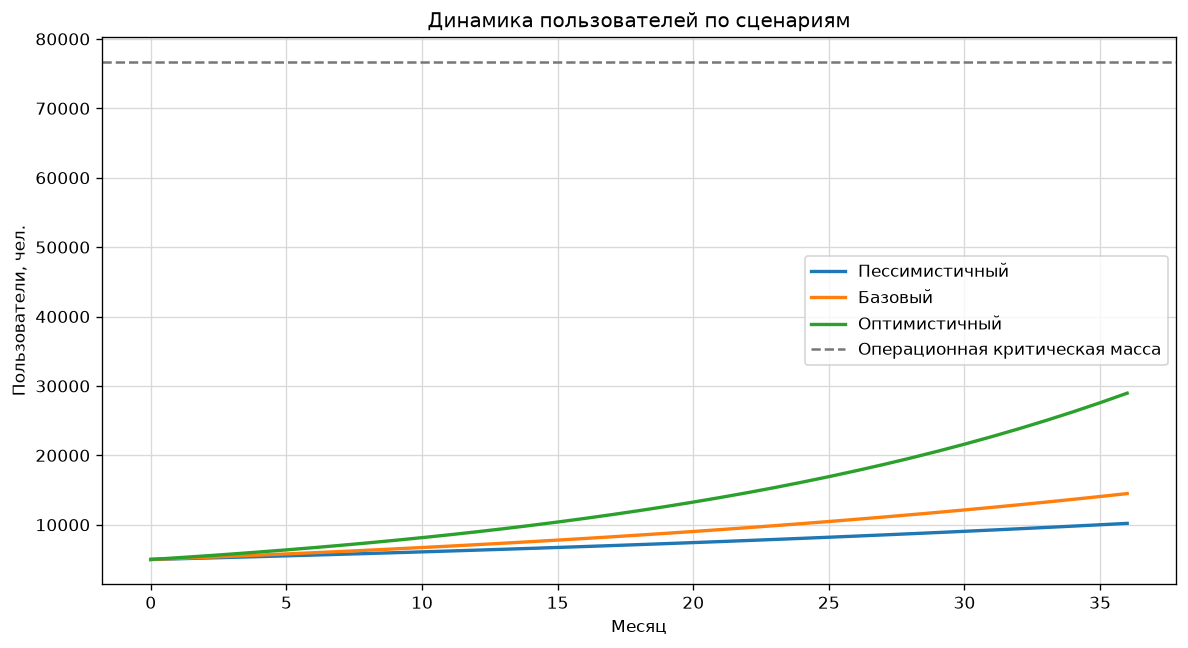

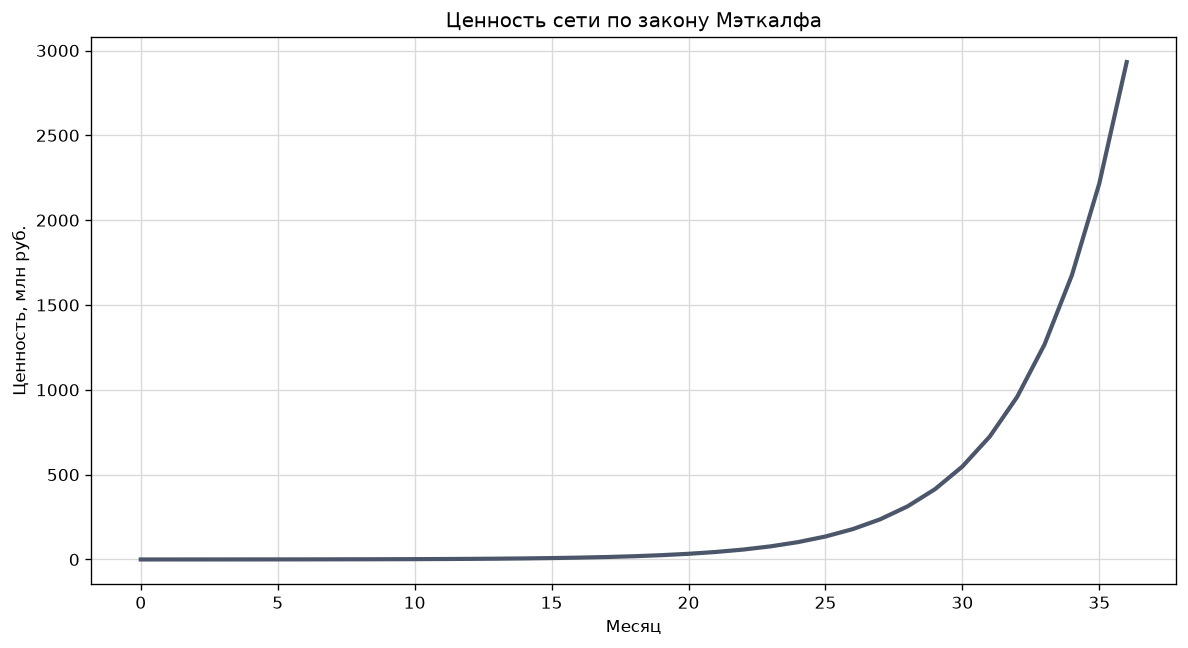

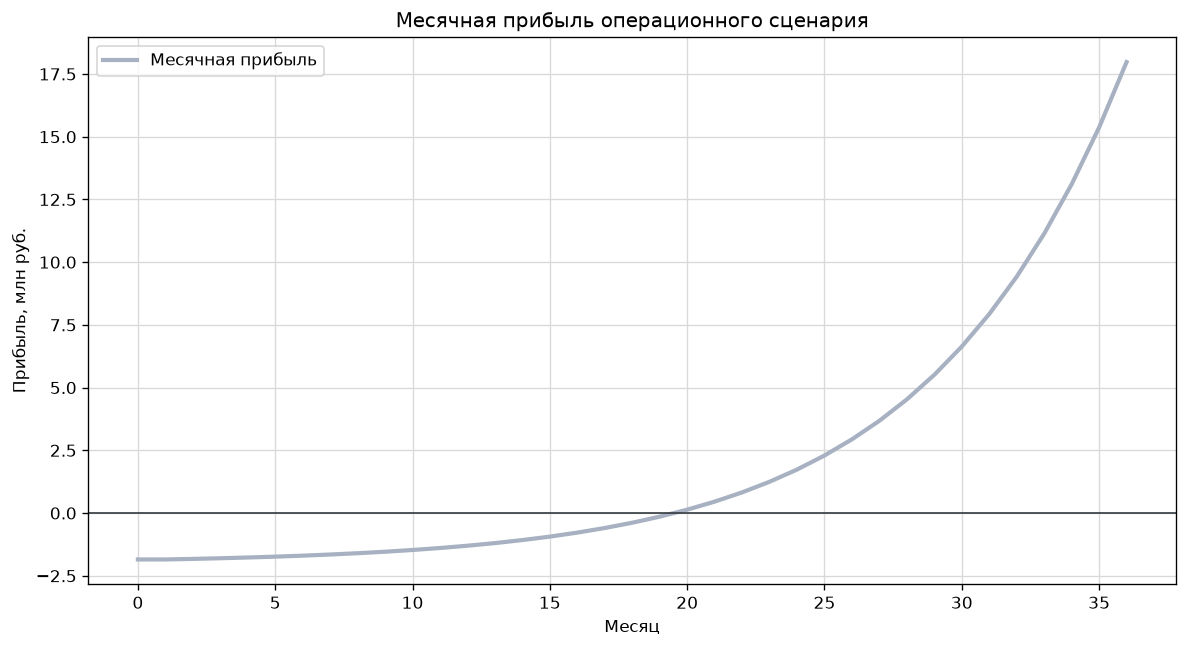

In [19]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for name, table in scenario_dfs.items(): ax.plot(table['month'], table['users'], linewidth=2, label=name)
ax.axhline(operational_critical if math.isfinite(operational_critical) else cfg['market_potential_users'], linestyle='--', color='#777777', label='Операционная критическая масса')
ax.set(title='Динамика пользователей по сценариям', xlabel='Месяц', ylabel='Пользователи, чел.')
ax.legend(); fig.tight_layout(); fig.savefig(figures_dir / 'task_02_users_scenarios.png', bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(df['month'], df['network_value'] / cfg['display_scale_rub'], color='#4C566A', linewidth=2.5)
ax.set(title='Ценность сети по закону Мэткалфа', xlabel='Месяц', ylabel='Ценность, млн руб.')
fig.tight_layout(); fig.savefig(figures_dir / 'task_02_network_value.png', bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(df['month'], df['profit'] / cfg['display_scale_rub'], color='#A7B1C2', linewidth=2.5, label='Месячная прибыль')
ax.axhline(0, color='#343A40', linewidth=1); ax.set(title='Месячная прибыль операционного сценария', xlabel='Месяц', ylabel='Прибыль, млн руб.')
ax.legend(); fig.tight_layout(); fig.savefig(figures_dir / 'task_02_profit.png', bbox_inches='tight'); plt.show()

## Часть 4. Стратегические выводы
### Вопрос 9
Определить объём маркетинговых инвестиций, необходимый для достижения операционной критической массы на шесть месяцев раньше.
### Вопрос 10
Сформулировать рекомендации по стратегии достижения критической массы.

In [20]:
if math.isfinite(operational_critical):
    base_target_month = months_to_target(operational_critical, cfg['growth_before_critical'], cfg['initial_users'])
    earlier_month = max(1, base_target_month - cfg['target_advance_months'])
    users_without_acceleration = cfg['initial_users'] * (1 + cfg['growth_before_critical']) ** earlier_month
    additional_users = max(operational_critical - users_without_acceleration, 0)
    marketing_investment = additional_users * operational_cac
else:
    base_target_month = earlier_month = users_without_acceleration = additional_users = marketing_investment = math.nan
strategy_table = pd.DataFrame({'Показатель':['Базовый месяц достижения операционной критической массы','Целевой месяц','Пользователи в целевом месяце без ускорения','Дополнительные пользователи','Маркетинговые инвестиции'],'Значение':[base_target_month,earlier_month,users_without_acceleration,additional_users,marketing_investment],'Единица':['мес.','мес.','чел.','чел.','руб.']})
display(strategy_table)
recommendations = pd.DataFrame([
    ('Вирусный маркетинг','Реферальные программы и приглашения',f"Снижение CAC; текущий порог: {max_cac_text}"),
    ('Локальный запуск','Запуск в одном районе города','Снижение постоянных затрат и проверка спроса малыми вложениями'),
    ('Партнёрство с местным бизнесом','Скидки и совместные предложения','Повышение ARPU и дополнительная ценность для пользователей'),
    ('Геймификация','Рейтинги, статусы и бейджи','Повышение удержания и вовлечённости; эффект нужно проверить по когортам'),
    ('Аналитика и A/B-тесты','Оптимизация воронки привлечения','Проверка конверсии и снижение CAC на фактических данных'),
], columns=['Стратегия','Описание','Ожидаемый эффект'])
display(recommendations)
display(Markdown(f"""**Ответ на вопросы 9–10.** При достижимом операционном пороге для ускорения на {cfg['target_advance_months']} месяцев требуется привлечь примерно **{fmt_num(additional_users)} дополнительных пользователей**, что при CAC {fmt_rub(operational_cac)} руб. составляет **{fmt_rub(marketing_investment)} руб.** Если строгий порог не существует, приоритетом становится не только маркетинг, но и изменение ARPU, CAC и затрат на поддержание."""))
final_table = pd.DataFrame({'Показатель':['Строгая критическая масса','Операционная критическая масса','Строгий NPV','Операционный NPV','Безубыточный ARPU','Минимальный рост'],'Значение':[critical_mass_text(strict_critical),critical_mass_text(operational_critical),strict_npv,base_npv,min_arpu,threshold_text(min_growth,'%')],'Единица':['чел.','чел.','руб.','руб.','руб./пользователь/мес.','%']})
display(final_table)

,Показатель,Значение,Единица
0,Базовый месяц достижения операционной критичес...,"20,00",мес.
1,Целевой месяц,"14,00",мес.
2,Пользователи в целевом месяце без ускорения,"35 378,53",чел.
3,Дополнительные пользователи,"41 288,14",чел.
4,Маркетинговые инвестиции,"1 238 644,14",руб.


,Стратегия,Описание,Ожидаемый эффект
0,Вирусный маркетинг,Реферальные программы и приглашения,"Снижение CAC; текущий порог: 124,00 руб./польз..."
1,Локальный запуск,Запуск в одном районе города,Снижение постоянных затрат и проверка спроса м...
2,Партнёрство с местным бизнесом,Скидки и совместные предложения,Повышение ARPU и дополнительная ценность для п...
3,Геймификация,"Рейтинги, статусы и бейджи",Повышение удержания и вовлечённости; эффект ну...
4,Аналитика и A/B-тесты,Оптимизация воронки привлечения,Проверка конверсии и снижение CAC на фактическ...


**Ответ на вопросы 9–10.** При достижимом операционном пороге для ускорения на 6 месяцев требуется привлечь примерно **41 288 дополнительных пользователей**, что при CAC 30 руб. составляет **1 238 644 руб.** Если строгий порог не существует, приоритетом становится не только маркетинг, но и изменение ARPU, CAC и затрат на поддержание.

,Показатель,Значение,Единица
0,Строгая критическая масса,85 185,чел.
1,Операционная критическая масса,76 667,чел.
2,Строгий NPV,"42 039 438,52",руб.
3,Операционный NPV,"53 401 043,92",руб.
4,Безубыточный ARPU,"17,74",руб./пользователь/мес.
5,Минимальный рост,"11,88%",%


In [21]:
status = 'экономически целесообразен' if base_npv >= 0 else 'экономически нецелесообразен'
display(Markdown(f"""## Заключение

В строгой модели критическая масса определяется из условия ARPU − CAC × g/(1+g) > 0. При исходном CAC **{fmt_rub(cfg['cac_rub'])} руб.** {strict_interpretation}

В операционном сценарии с CAC **{fmt_rub(operational_cac)} руб.** критическая масса составляет **{critical_mass_text(operational_critical)} пользователей** и достигается примерно на **{operational_months}-м месяце** при сохранении темпа роста. Операционный NPV за {cfg['horizon_months']} месяцев равен **{fmt_rub(base_npv, 2)} руб.**, поэтому проект при текущих параметрах **{status}**.

Ключевые рычаги: повышать ARPU, снижать CAC, ускорять органический рост и снижать затраты на поддержание. Закон Мэткалфа показывает потенциальную ценность сетевого эффекта, но не заменяет анализ прибыли и денежных потоков.

Ограничения: модель не учитывает отток, сезонность, налоги, капитальные затраты, маржу после переменных расходов и изменение CAC при масштабировании."""))

## Заключение

В строгой модели критическая масса определяется из условия ARPU − CAC × g/(1+g) > 0. При исходном CAC **50 руб.** критическая масса существует и достижима в пределах рынка.

В операционном сценарии с CAC **30 руб.** критическая масса составляет **76 667 пользователей** и достигается примерно на **20-м месяце** при сохранении темпа роста. Операционный NPV за 36 месяцев равен **53 401 043,92 руб.**, поэтому проект при текущих параметрах **экономически целесообразен**.

Ключевые рычаги: повышать ARPU, снижать CAC, ускорять органический рост и снижать затраты на поддержание. Закон Мэткалфа показывает потенциальную ценность сетевого эффекта, но не заменяет анализ прибыли и денежных потоков.

Ограничения: модель не учитывает отток, сезонность, налоги, капитальные затраты, маржу после переменных расходов и изменение CAC при масштабировании.

In [22]:
%%capture
# Экспорт HTML-отчёта без отображения кода.
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_02_report task_02_social_network.ipynb